# 1121 — Why strong dephasing brings back higher Fock states

**Observation (1113 sections 7–8, 2026-11-15).** In the best-Fock-state phase diagram, the optimum first falls to the vacuum as dephasing grows, then **returns to higher n** at strong dephasing (e.g. β = 1, Γc·t = 0.1: n = 2 from Γφt ≈ 50, n = 3 near 300). This notebook tests that re-entrance and its explanation.

**What the Notion hub says** ([QFI/QCRB hub](https://app.notion.com/p/41ae1a5c7b14818e8ca7cf5e53c3b0a0), read 2026-11-21):

| # | Point |
| --- | --- | 
| O1 | The optimal-Fock-state map and the high-dephasing re-entrant regions are research leads that need independent convergence tests and benchmarking before they count as results |
| O2 | The strong-noise scaling coefficients depend on the signal and are not universal constants | 
| O3 | Eq. 139's (Γφt)² scaling holds, but its constant depends on β and lies below K_n | 

- **M1.** Under strong dephasing, the coherent drive acts on the populations like a hot bath of strength Γβ = 4β²/(Γφt). Near Γφt ~ 4β² this bath is strong (above the 0.117 break-even), so the vacuum wins.
- **M2.** As Γφt grows, Γβ falls as 1/Γφt (Zeno suppression), the effective bath switches off, and the state stays near |n⟩.
- **M3.** The signal is then read largely through the contrast, whose figure of merit 16α⁴V_n²/(1 − V_n²) peaks at large α, where only the higher Fock states keep Laguerre lobes. That is why the state that returns has **higher** n.
- **M4.** Real heating adds to Γβ and damps large α, so the return survives only for Γh·t ≲ O(0.1/n).

**Plan.** P1: phase diagram over (Γφt, β), engine vs closed form. P2: convergence. P3: the effective hot bath, checked on populations and QCRB. P4: phase vs contrast figure of merit. P5: dependence on β, and no re-entrance as β → 0. P6: heating limits the return.

All plots are saved to `plots/1121/B*.png` and embedded below. Model: ideal signal drive, Lindblad noise, instantaneous readout (the effective model validated in 1120). r = 0, n ≤ 5.

In [1]:
using Pkg
Pkg.activate(@__DIR__)                      # this repo's Project.toml / Manifest.toml (same environment as 1113)
ENV["MPLBACKEND"] = "agg"
using LinearAlgebra, Printf
using PyPlot

BLAS.set_num_threads(1)                     # 61–121-level products are faster single-threaded; parallelism is over grid points
println("Julia threads: ", Threads.nthreads(), "   (start Julia with -t auto; 1 thread takes about 8× longer)")

Julia threads: 8   (start Julia with -t auto; 1 thread takes about 8× longer)

## 1. Closed forms and engine (copied from 1113 sections 1–2)

Plain Fock states (r = 0), n ≤ 5. With the drive only, 61 levels are enough (the tail is printed with every map).

In [2]:
# ---- closed forms (1113 section 1): eq. 33 / 74 / 106. Gc, Gh are Γ_c·t_sig and Γ_h·t_sig ----
function laguerre(n::Int, x::Real)
    n == 0 && return 1.0
    Lm, L = 1.0, 1.0 - x
    for k in 1:(n-1)
        Lm, L = L, ((2k + 1 - x) * L - k * Lm) / (k + 1)
    end
    return L
end

function qcrb_theory(α::Real, n::Int; r::Real=0.0, Gc::Real=0.0, Gh::Real=0.0)
    K = Gc - Gh
    decay = exp(-K)
    diffusion = abs(K) < 1e-9 ? (Gc + Gh) : (Gc + Gh) * (1 - decay) / K     # (2n̄+1)(1 − e^{−Γt})
    f = abs(K) < 1e-9 ? 1.0 - K / 4 : (2 / K) * (1 - exp(-K / 2))           # laser-drift factor, eq. 71
    B = diffusion + decay * exp(-2r)                                        # B_var, eq. 107
    L = laguerre(n, 4α^2 * decay * exp(-2r))
    return exp(4α^2 * B) / (16α^2 * f^2 * L^2)
end

# ---- engine (1113 section 2, unchanged) ----
function displace_matrix(ξ::Number, d::Int; pad::Int=2d)
    a = diagm(1 => sqrt.(1:(pad-1)))
    return exp(ξ * a' - conj(ξ) * a)[1:d, 1:d]
end

# S(r)|n> with the QuantumOptics.squeeze(b, r) sign convention (r > 0 improves sensitivity, eq. 33)
function squeezed_fock(n::Int, r::Real, d::Int; pad::Int=2d)
    v = zeros(pad); v[n+1] = 1.0
    if r != 0
        a = diagm(1 => sqrt.(1:(pad-1)))
        v = exp((r / 2) * (a^2 - (a')^2)) * v
    end
    v = v[1:d]
    return v ./ norm(v)
end

# Exact dephasing + cooling + heating map over a fraction `frac` of the exposure, one small matrix per diagonal k.
struct NoiseStep
    E::Vector{Matrix{Float64}}
    diagonal_only::Bool
    mask::Matrix{Float64}
end

function NoiseStep(Gphi::Real, Gc::Real, Gh::Real, frac::Real, d::Int)
    N = d - 1
    mask = [exp(-0.5 * Gphi * frac * (i - j)^2) for i in 1:d, j in 1:d]            # eq. 124 / 145
    (Gc == 0 && Gh == 0) && return NoiseStep(Matrix{Float64}[], true, mask)
    up(j) = j < N ? j + 1.0 : 0.0
    E = Vector{Matrix{Float64}}(undef, d)
    for k in 0:N
        len = N - k + 1
        T = zeros(len, len)
        for i in 1:len
            m = i - 1
            T[i, i] = -0.5 * Gc * (2m + k) - 0.5 * Gh * (up(m) + up(m + k)) - 0.5 * Gphi * k^2
            i < len && (T[i, i+1] = Gc * sqrt((m + 1) * (m + k + 1)))               # cooling, eq. 142
            i > 1 && (T[i, i-1] = Gh * sqrt(m * (m + k)))                           # heating, eq. 143
        end
        E[k+1] = exp(T .* frac)
    end
    return NoiseStep(E, false, mask)
end

function apply_noise!(ρ::Matrix{Float64}, ns::NoiseStep, buf::Vector{Float64})
    if ns.diagonal_only
        ρ .*= ns.mask
        return ρ
    end
    d = size(ρ, 1)
    @inbounds for k in 0:(d-1)
        len = d - k
        Ek = ns.E[k+1]
        for i in 1:len
            s = 0.0
            for j in 1:len
                s += Ek[i, j] * ρ[j, j+k]
            end
            buf[i] = s
        end
        for i in 1:len
            ρ[i, i+k] = buf[i]; ρ[i+k, i] = buf[i]
        end
    end
    return ρ
end

default_steps(Gphi, Gc, Gh) = max(64, ceil(Int, 6 * max(Gphi, Gc, Gh)))

struct Drive
    D::Matrix{Float64}; Dt::Matrix{Float64}; G::Matrix{Float64}
    full::NoiseStep; half::NoiseStep; steps::Int
end

function Drive(β::Real, Gphi::Real, Gc::Real, Gh::Real; steps::Int=default_steps(Gphi, Gc, Gh), d::Int)
    a = diagm(1 => sqrt.(1:(d-1)))
    G = a' - a
    D = exp((β / steps) .* G)
    return Drive(D, Matrix(D'), G, NoiseStep(Gphi, Gc, Gh, 1 / steps, d), NoiseStep(Gphi, Gc, Gh, 0.5 / steps, d), steps)
end

# ρ(β) and ∂ρ/∂β after the noisy drive. Strang split: noise(½)·[drive·noise]^(S−1)·drive·noise(½).
function propagate(ψ0::Vector{Float64}, drv::Drive)
    d = length(ψ0); S = drv.steps
    ρ = ψ0 * ψ0'; dρ = zeros(d, d)
    t1 = similar(ρ); t2 = similar(ρ); buf = zeros(d)
    apply_noise!(ρ, drv.half, buf)
    for s in 1:S
        mul!(t1, drv.D, ρ);  mul!(ρ, t1, drv.Dt)
        mul!(t1, drv.D, dρ); mul!(dρ, t1, drv.Dt)
        mul!(t1, drv.G, ρ);  mul!(t2, ρ, drv.G)
        @. dρ += (t1 - t2) / S
        ns = s == S ? drv.half : drv.full
        apply_noise!(ρ, ns, buf); apply_noise!(dρ, ns, buf)
    end
    return ρ, dρ
end

# eq. 149–150: C = Tr[D(2iα)ρ],  QFI = |∂C|² + Re(C*∂C)² / (1 − |C|²)
function qcrb_from_state(ρ::Matrix{Float64}, dρ::Matrix{Float64}, V::Matrix{ComplexF64})
    C = zero(ComplexF64); dC = zero(ComplexF64)
    @inbounds for j in axes(V, 2), i in axes(V, 1)
        C += V[j, i] * ρ[i, j]; dC += V[j, i] * dρ[i, j]
    end
    qfi = abs2(dC) + real(conj(C) * dC)^2 / max(1 - abs2(C), 1e-300)
    return qfi > 0 ? 1 / qfi : Inf
end

readout_matrices(αs, d::Int) = [displace_matrix(2im * a, d) for a in αs]

# Squeezing stretches the optimal readout by e^r (α_opt = e^r √y_opt / 2, eq. 79), so the α grid is scaled per r.
alpha_grid(r; base=collect(0.05:0.015:2.6)) = base .* exp(r)

tail_population(ρ) = sum(@view ρ[diagind(ρ)[end-4:end]])      # population in the top 5 Fock levels

## 2. Strong-dephasing closed form and helpers

The closed form is Block 4 of `~/Downloads/qcrb_additions/additions.tex` (2026-11-15). In the strong-dephasing regime the coherences are slaved to the populations, ρ_{m+1,m} = (2β/Γφt)√(m+1)(p_m − p_{m+1}). Eliminating them leaves the population equation of a **hot bath**, with equal up and down rates

Γβ = 4β² / (Γφ t_sig).

A real hot bath adds to it: D = Γh t + Γβ. The envelope is V_n = e^{−2α²(1+2D)} L_n(4α²), and

QCRB_n(α) = (Γφt)² / (64 α² V_n²) · [1 + 16 α² β² / (1 − V_n²)]⁻¹.

It is valid for Γφt ≫ 4β²(n+1); below, it is drawn only where Γφt > max(40β², 10).

In [3]:
const N_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2"]   # same n colours as 1113
const mcolors = PyPlot.matplotlib.colors
const PLOT_DIR = joinpath(@__DIR__, "plots", "1121"); mkpath(PLOT_DIR)
const D_FOCK = 61
const N_VALS = collect(0:5)

# ---- strong-dephasing closed form (additions.tex Block 4, derived 2026-11-15) ----
# Eliminating the coherences turns drive + dephasing into a hot bath of strength Γβ = 4β²/(Γφ t).
# For a real hot bath Γc = Γh it adds linearly: D = Γh t + Γβ, and
#   V_n = e^{-2α²(1+2D)} L_n(4α²),   QCRB_n(α) = (Γφt)² / (64 α² V_n²) · [1 + 16 α² β² / (1 − V_n²)]⁻¹
gamma_beta(β, Gphi) = 4β^2 / Gphi
V_strong(α, n; β, Gphi, Gh=0.0) = exp(-2α^2 * (1 + 2 * (Gh + gamma_beta(β, Gphi)))) * laguerre(n, 4α^2)
function qcrb_strong(α, n; β, Gphi, Gh=0.0)
    V = V_strong(α, n; β=β, Gphi=Gphi, Gh=Gh)
    return Gphi^2 / (64α^2 * V^2) / (1 + 16α^2 * β^2 / max(1 - V^2, 1e-300))
end
# validity: coherences slaved to populations needs Γφt ≫ 1 and Γφt ≫ 4β²(n+1)
strong_valid(β, Gphi) = Gphi > max(40β^2, 10.0)
min_qcrb_strong(n; β, Gphi, Gh=0.0, αs=0.02:0.002:4.0) = minimum(qcrb_strong(a, n; β=β, Gphi=Gphi, Gh=Gh) for a in αs)

# ---- engine helpers: min over α for every n at one noise point ----
const ALPHAS = collect(0.05:0.015:3.2)
const VS = readout_matrices(ALPHAS, D_FOCK)
const PSIS = [squeezed_fock(n, 0.0, D_FOCK) for n in N_VALS]

function min_qcrbs(β, Gphi, Gc, Gh; d=D_FOCK, αs=ALPHAS, Vs=VS, ψs=PSIS, steps=default_steps(Gphi, Gc, Gh))
    drv = Drive(β, Gphi, Gc, Gh; d=d, steps=steps)
    q = zeros(length(ψs)); tail = 0.0
    for k in eachindex(ψs)
        ρ, dρ = propagate(ψs[k], drv)
        q[k] = minimum(qcrb_from_state(ρ, dρ, V) for V in Vs)
        tail = max(tail, tail_population(ρ))
    end
    return q, tail
end

function setup_log_axes!(ax, xl, yl, ttl)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(xl, fontsize=11); ax.set_ylabel(yl, fontsize=11); ax.set_title(ttl, fontsize=11)
end
println("strong-dephasing closed form and engine helpers loaded; n = $(N_VALS), d = $(D_FOCK)")

strong-dephasing closed form and engine helpers loaded; n = [0, 1, 2, 3, 4, 5], d = 61

## 3. P1: the phase diagram shows the re-entrance

Best n over (Γφt, β), no cooling or heating. The black dotted lines are the closed-form boundaries (shown where Γφt > max(40β², 10), right of the thin white line). The white dashed line is where the effective bath strength Γβ equals 0.117, the hot-bath break-even of n = 1 against n = 0.

(Γφt, β) map, Γc·t = 0, Γh·t = 0: 36 × 20 points × 6 states in 133 s; max tail 2.4e-16
closed-form n* = engine n* on 208 / 220 points with Γφt > max(40β², 10)
β = 0.03: n* along increasing Γφt = 5
β = 0.27: n* along increasing Γφt = 5
β = 0.90: n* along increasing Γφt = 5 → 3 → 2 → 1 → 2 → 3 → 4 → 5
β = 2.22: n* along increasing Γφt = 5 → 4 → 3 → 2 → 1 → 0 → 1 → 2 → 3 → 4 → 5

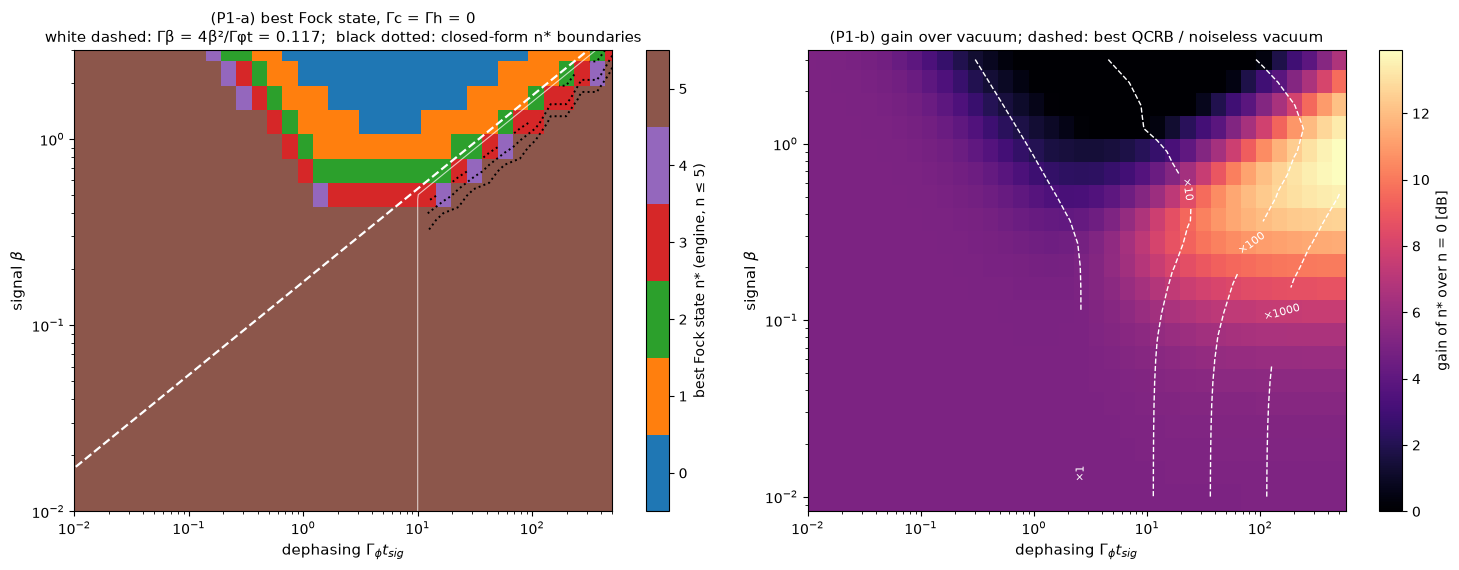

In [4]:
# P1. Phase diagram of the best Fock state over (dephasing, signal size), no cooling or heating.
function phase_map_beta(; gphi_range=(1e-2, 500.0), beta_range=(0.01, 3.0), nx=36, ny=20, Gc=0.0, Gh=0.0)
    gps = 10 .^ range(log10(gphi_range[1]), log10(gphi_range[2]), length=nx)
    bs = 10 .^ range(log10(beta_range[1]), log10(beta_range[2]), length=ny)
    Q = fill(NaN, length(N_VALS), ny, nx); tails = zeros(ny, nx)
    t0 = time()
    GC.gc()   # finalize Python (PyPlot) objects on the main thread first: a PyCall finalizer on a worker thread segfaults
    Threads.@threads :dynamic for idx in 1:(nx*ny)
        iy, ix = fldmod1(idx, nx)
        q, tl = min_qcrbs(bs[iy], gps[ix], Gc, Gh)
        Q[:, iy, ix] = q; tails[iy, ix] = tl
    end
    @printf("(Γφt, β) map, Γc·t = %g, Γh·t = %g: %d × %d points × %d states in %.0f s; max tail %.1e\n",
            Gc, Gh, nx, ny, length(N_VALS), time() - t0, maximum(tails))
    return (gps=gps, bs=bs, Q=Q, tails=tails)
end

nstar_of(Q) = Float64[N_VALS[argmin(@view Q[:, i, j])] for i in axes(Q, 2), j in axes(Q, 3)]

# closed-form n* from the strong-dephasing formula, on the same grid (meaningful only where Γφt ≫ 4β²(n+1))
# exactly one of β, Gh is given; the y axis supplies the other
function nstar_strong(gps, ys; β=nothing, Gh=nothing)
    (β === nothing) == (Gh === nothing) && error("give exactly one of β or Gh")
    out = fill(NaN, length(ys), length(gps))
    for (i, y) in enumerate(ys), (j, g) in enumerate(gps)
        b = β === nothing ? y : β; h = Gh === nothing ? y : Gh
        out[i, j] = N_VALS[argmin([min_qcrb_strong(n; β=b, Gphi=g, Gh=h) for n in N_VALS])]
    end
    return out
end

pm = phase_map_beta()
ns_engine = nstar_of(pm.Q)
ns_closed = nstar_strong(pm.gps, pm.bs; Gh=0.0)
valid_strong = [strong_valid(b, g) for b in pm.bs, g in pm.gps]     # Γφt > max(40β², 10): deep in the strong-dephasing regime
agree = count(ns_engine[valid_strong] .== ns_closed[valid_strong])
@printf("closed-form n* = engine n* on %d / %d points with Γφt > max(40β², 10)\n", agree, count(valid_strong))

fig, (ax1, ax2) = subplots(1, 2, figsize=(15, 5.8))
cmap = mcolors.ListedColormap(N_COLORS[1:length(N_VALS)])
im1 = ax1.pcolormesh(pm.gps, pm.bs, ns_engine, cmap=cmap, vmin=-0.5, vmax=N_VALS[end] + 0.5, shading="nearest")
cb1 = fig.colorbar(im1, ax=ax1, ticks=N_VALS); cb1.set_label("best Fock state n* (engine, n ≤ $(N_VALS[end]))")
cl = copy(ns_closed); cl[.!valid_strong] .= NaN
ax1.contour(pm.gps, pm.bs, cl, levels=N_VALS[1:end-1] .+ 0.5, colors="black", linewidths=1.4, linestyles=":")
bb = 10 .^ range(log10(pm.bs[1]), log10(pm.bs[end]), length=100)
ax1.plot(4bb .^ 2 ./ 0.117, bb, "w--", lw=1.6)                        # Γβ = 0.117: hot-bath break-even of n = 1 vs n = 0
ax1.plot(max.(40bb .^ 2, 10.0), bb, color="white", lw=0.8, ls="-", alpha=0.7)    # right of this thin line the closed form is valid
ax1.set_xlim(pm.gps[1], pm.gps[end]); ax1.set_ylim(pm.bs[1], pm.bs[end])
setup_log_axes!(ax1, L"dephasing $\Gamma_\phi t_{sig}$", L"signal $\beta$",
                "(P1-a) best Fock state, Γc = Γh = 0\nwhite dashed: Γβ = 4β²/Γφt = 0.117;  black dotted: closed-form n* boundaries")
gain = 10 .* log10.(pm.Q[1, :, :] ./ dropdims(minimum(pm.Q, dims=1), dims=1))
im2 = ax2.pcolormesh(pm.gps, pm.bs, gain, cmap="magma", vmin=0, shading="nearest")
cb2 = fig.colorbar(im2, ax=ax2); cb2.set_label("gain of n* over n = 0 [dB]")
best = dropdims(minimum(pm.Q, dims=1), dims=1)
cs = ax2.contour(pm.gps, pm.bs, log10.(best ./ (exp(1) / 4)), levels=[0.0, 1.0, 2.0, 3.0], colors="white", linewidths=1.0, linestyles="--")
ax2.clabel(cs, fmt=Dict(0.0 => "×1", 1.0 => "×10", 2.0 => "×100", 3.0 => "×1000"), fontsize=8)
setup_log_axes!(ax2, L"dephasing $\Gamma_\phi t_{sig}$", L"signal $\beta$", "(P1-b) gain over vacuum; dashed: best QCRB / noiseless vacuum")
tight_layout(); savefig(joinpath(PLOT_DIR, "dephasing_P1_phase_beta.png"), dpi=130, bbox_inches="tight"); display(fig); close(fig)

for b in (0.03, 0.3, 1.0, 2.0)                                       # the re-entrance read off along fixed-β rows
    i = argmin(abs.(log.(pm.bs) .- log(b)))
    row = ns_engine[i, :]; seq = [Int(row[1])]
    for v in row; Int(v) != seq[end] && push!(seq, Int(v)); end
    @printf("β = %.2f: n* along increasing Γφt = %s\n", pm.bs[i], join(seq, " → "))
end

## 4. P2: convergence (the Notion §10 guardrail)

The hub says the optimal-Fock map and its high-dephasing re-entrant regions are "research leads requiring independent convergence and benchmarking". This cell recomputes every 3rd grid point with a larger cutoff (61 → 91), twice the time steps, and a wider, finer α grid (to 4.5 in steps of 0.01). The benchmark against an independent model is the closed form in P1 / P3.

In [5]:
# P2. Convergence of the phase diagram (the check the Notion §10 guardrail asks for).
# On every 3rd grid point: cutoff 61 → 91, time steps × 2, α grid 0.05:0.015:3.2 → 0.03:0.01:4.5.
# A flip of n* only counts if the two best states differ by more than 1 % in the reference run.
function convergence_check(pm; stride=3)
    αs2 = collect(0.03:0.01:4.5)
    d2 = 91; Vs2 = readout_matrices(αs2, d2); ψs2 = [squeezed_fock(n, 0.0, d2) for n in N_VALS]
    pts = [(i, j) for i in 1:stride:length(pm.bs), j in 1:stride:length(pm.gps)]
    res = Vector{NTuple{4,Float64}}(undef, length(pts))
    t0 = time()
    GC.gc()   # finalize Python (PyPlot) objects on the main thread first: a PyCall finalizer on a worker thread segfaults
    Threads.@threads :dynamic for m in eachindex(pts)
        i, j = pts[m]; b, g = pm.bs[i], pm.gps[j]
        q2, _ = min_qcrbs(b, g, 0.0, 0.0; d=d2, αs=αs2, Vs=Vs2, ψs=ψs2, steps=2default_steps(g, 0.0, 0.0))
        q1 = pm.Q[:, i, j]
        s = sort(q1)
        res[m] = (maximum(abs.(q2 ./ q1 .- 1)), Float64(argmin(q1) != argmin(q2)), s[2] / s[1] - 1, 0.0)
    end
    maxdev = maximum(first.(res)); flips = [r for r in res if r[2] == 1]
    real_flips = count(r -> r[3] > 0.01, flips)
    @printf("%d points in %.0f s: max |ΔQCRB|/QCRB = %.2e;  n* flips: %d, of which %d with a > 1 %% margin\n",
            length(pts), time() - t0, maxdev, length(flips), real_flips)
    return res
end
conv = convergence_check(pm);

84 points in 218 s: max |ΔQCRB|/QCRB = 3.15e-03;  n* flips: 0, of which 0 with a > 1 % margin

## 5. P3: mechanism, part 1. The dephased drive acts as a hot bath

(a) Run the engine with drive + dephasing, then separately apply only a hot bath Γc = Γh = Γβ with no drive at all. If the elimination is right, the Fock populations agree.
(b) Full QCRB(α) curves, engine against the closed form, and the n* each one picks.

This explains the **middle** of the diagram. Γβ is largest when Γφt ~ 4β². A hot bath stronger than about 0.12 removes every Fock advantage, so n* = 0 there. As Γφt grows, Γβ falls as 1/Γφt (Zeno suppression of the drive): the bath switches off and the Fock states come back.

(a) populations, β = 1.0, |n = 2>: trace distance of the diagonals, engine vs hot bath Γβ
    Γφt =    10  Γβ = 0.4000:  ½Σ|Δp| = 8.12e-02   (p_n stays 0.275)
    Γφt =    30  Γβ = 0.1333:  ½Σ|Δp| = 8.36e-03   (p_n stays 0.578)
    Γφt =   300  Γβ = 0.0133:  ½Σ|Δp| = 3.32e-04   (p_n stays 0.937)
(b) min over α: engine vs strong-dephasing closed form, β = 1.0
   Γφt |    n=0 eng / closed |   n=1 eng / closed |   n=2 eng / closed |   n=3 eng / closed
    10 |     7.797 /    6.349 |    5.323 /    8.553 |    9.962 /    10.59 |    10.03 /    13.94 |  n* engine 1, closed 0
    30 |     34.28 /    29.99 |    13.79 /    13.39 |    12.94 /    14.18 |    16.88 /    20.54 |  n* engine 2, closed 1
   100 |     260.9 /    247.4 |    71.08 /    68.03 |    42.73 /    41.45 |    33.68 /    33.16 |  n* engine 5, closed 5
   300 |      2063 /     2025 |    485.4 /    476.5 |    248.5 /    244.3 |    165.7 /    163.1 |  n* engine 5, closed 5

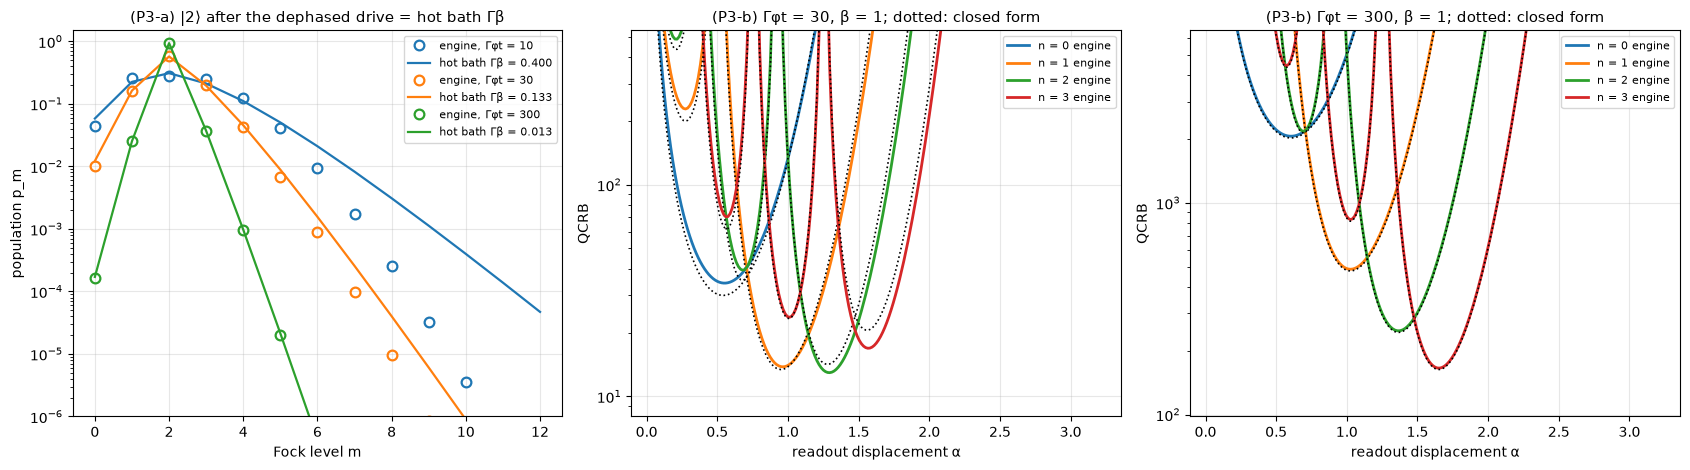

In [6]:
# P3. Mechanism: the dephased drive is a hot bath of strength Γβ = 4β²/(Γφ t).
# (a) Fock populations after the noisy drive (engine) vs a hot bath Γc = Γh = Γβ with no drive at all.
# (b) QCRB(α): engine vs the strong-dephasing closed form, and the n* each predicts.
β_m, n_m = 1.0, 2
fig, axs = subplots(1, 3, figsize=(17, 4.8))
println("(a) populations, β = $β_m, |n = $n_m>: trace distance of the diagonals, engine vs hot bath Γβ")
for (c, g) in zip(("#1f77b4", "#ff7f0e", "#2ca02c"), (10.0, 30.0, 300.0))
    ρd, _ = propagate(PSIS[n_m+1], Drive(β_m, g, 0.0, 0.0; d=D_FOCK))
    Γb = gamma_beta(β_m, g)
    ρb, _ = propagate(PSIS[n_m+1], Drive(0.0, 0.0, Γb, Γb; d=D_FOCK))
    pd, pb = diag(ρd), diag(ρb)
    @printf("    Γφt = %5.0f  Γβ = %.4f:  ½Σ|Δp| = %.2e   (p_n stays %.3f)\n", g, Γb, 0.5sum(abs.(pd .- pb)), pd[n_m+1])
    axs[1].plot(0:12, pd[1:13], "o", color=c, ms=7, mfc="none", mew=1.6, label=@sprintf("engine, Γφt = %g", g))
    axs[1].plot(0:12, pb[1:13], "-", color=c, lw=1.6, label=@sprintf("hot bath Γβ = %.3f", Γb))
end
axs[1].set_yscale("log"); axs[1].set_ylim(1e-6, 1.5); axs[1].grid(alpha=0.3)
axs[1].set_xlabel("Fock level m"); axs[1].set_ylabel("population p_m")
axs[1].set_title("(P3-a) |2⟩ after the dephased drive = hot bath Γβ", fontsize=11); axs[1].legend(fontsize=8)

println("(b) min over α: engine vs strong-dephasing closed form, β = $β_m")
@printf("%6s | %s\n", "Γφt", join([@sprintf("   n=%d eng / closed", n) for n in N_VALS[1:4]], " |"))
for g in (10.0, 30.0, 100.0, 300.0)
    q, _ = min_qcrbs(β_m, g, 0.0, 0.0)
    qc = [min_qcrb_strong(n; β=β_m, Gphi=g) for n in N_VALS]
    @printf("%6.0f | %s |  n* engine %d, closed %d\n", g, join([@sprintf(" %8.4g / %8.4g", q[k], qc[k]) for k in 1:4], " |"),
            N_VALS[argmin(q)], N_VALS[argmin(qc)])
end
for (ax, g) in zip(axs[2:3], (30.0, 300.0))
    drv = Drive(β_m, g, 0.0, 0.0; d=D_FOCK)
    for n in 0:3
        ρ, dρ = propagate(PSIS[n+1], drv)
        ax.plot(ALPHAS, [qcrb_from_state(ρ, dρ, V) for V in VS], "-", color=N_COLORS[n+1], lw=2, label="n = $n engine")
        ax.plot(ALPHAS, [qcrb_strong(a, n; β=β_m, Gphi=g) for a in ALPHAS], ":", color="black", lw=1.2)
    end
    lo = minimum(min_qcrb_strong(n; β=β_m, Gphi=g) for n in 0:3)
    ax.set_yscale("log"); ax.set_ylim(0.6lo, 40lo); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper right")
    ax.set_xlabel("readout displacement α"); ax.set_ylabel("QCRB")
    ax.set_title(@sprintf("(P3-b) Γφt = %g, β = %g; dotted: closed form", g, β_m), fontsize=11)
end
tight_layout(); savefig(joinpath(PLOT_DIR, "dephasing_P3_mechanism_hot_bath.png"), dpi=130, bbox_inches="tight"); display(fig); close(fig)

## 6. P4: mechanism, part 2. Why the state that returns is a higher Fock state

With the effective bath switched off, the strong-dephasing QFI has two parts: a phase term α²V_n² (the only one in the draft's eq. 139) and a contrast term β²·16α⁴V_n²/(1 − V_n²). The contrast term peaks at large α, where only the higher Fock states still have Laguerre lobes. So once the signal is read mostly through the contrast, larger n wins by more than it does in the noiseless phase-only case.

 n | max phase term (α*) | max contrast term (α*)
 0 |   0.092  (0.50)     |    0.65  (0.63)
 1 |   0.167  (0.97)     |    3.21  (1.04)
 2 |   0.211  (1.33)     |    6.98  (1.38)
 3 |   0.244  (1.63)     |   11.59  (1.66)
 4 |   0.270  (1.88)     |   16.84  (1.91)
 5 |   0.293  (2.11)     |   22.63  (2.14)

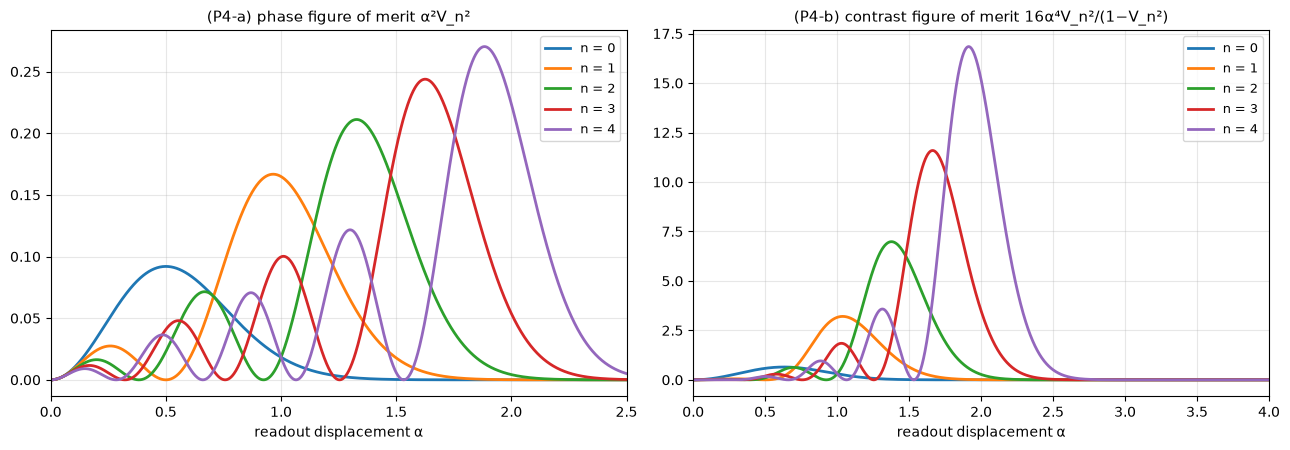

In [7]:
# P4. Why the returning state is a HIGHER Fock state: at strong dephasing the signal is read from the
# contrast as well as the phase. With V_n = e^{-2α²} L_n(4α²) (bath switched off, Γβ → 0):
#   phase term     α² V_n²                 (the only term in eq. 139's K_n)
#   contrast term  β² · 16 α⁴ V_n² / (1 − V_n²)
# The contrast term weights large α, where only higher n keep Laguerre lobes.
αf = collect(0.01:0.002:4.0)
Vn(α, n) = exp(-2α^2) * laguerre(n, 4α^2)
phase_fom(α, n) = α^2 * Vn(α, n)^2
contrast_fom(α, n) = 16α^4 * Vn(α, n)^2 / max(1 - Vn(α, n)^2, 1e-300)
println(" n | max phase term (α*) | max contrast term (α*)")
for n in N_VALS
    p = [phase_fom(a, n) for a in αf]; c = [contrast_fom(a, n) for a in αf]
    @printf(" %d | %7.3f  (%.2f)     | %7.2f  (%.2f)\n", n, maximum(p), αf[argmax(p)], maximum(c), αf[argmax(c)])
end
fig, (ax1, ax2) = subplots(1, 2, figsize=(13, 4.6))
for n in 0:4
    ax1.plot(αf, [phase_fom(a, n) for a in αf], color=N_COLORS[n+1], lw=2, label="n = $n")
    ax2.plot(αf, [contrast_fom(a, n) for a in αf], color=N_COLORS[n+1], lw=2, label="n = $n")
end
ax1.set_title("(P4-a) phase figure of merit α²V_n²", fontsize=11); ax2.set_title("(P4-b) contrast figure of merit 16α⁴V_n²/(1−V_n²)", fontsize=11)
for ax in (ax1, ax2); ax.set_xlabel("readout displacement α"); ax.grid(alpha=0.3); ax.legend(fontsize=9); end
ax1.set_xlim(0, 2.5); ax2.set_xlim(0, 4)
tight_layout(); savefig(joinpath(PLOT_DIR, "dephasing_P4_phase_vs_contrast_fom.png"), dpi=130, bbox_inches="tight"); display(fig); close(fig)

## 7. P5: the effect depends on the signal size (Notion §3)

The hub (§3, from ChatGPT) says the strong-noise coefficients "depend on the signal and are not simply universal constants". Both mechanisms above scale with β: Γβ ∝ β², and the contrast term ∝ β². So for β → 0 there should be no re-entrance at all. In that limit the dephasing multiplies every state's QCRB by the same factor 1/f², with f = (2/Γφt)(1 − e^{−Γφt/2}), so the ranking cannot change.

small signal β = 0.002: QCRB_n(Γφt) / QCRB_n(0) · f²  (1 means the 1/f² law holds; same for every n)
  Γφt =    0.1:  1.00000  1.00000  1.00000  1.00000  1.00000  1.00000
  Γφt =    1.0:  1.00001  1.00001  1.00001  1.00001  1.00001  1.00001
  Γφt =   10.0:  1.00050  1.00048  1.00046  1.00044  1.00042  1.00040
  Γφt =  100.0:  1.00056  1.00051  1.00046  1.00041  1.00035  1.00030

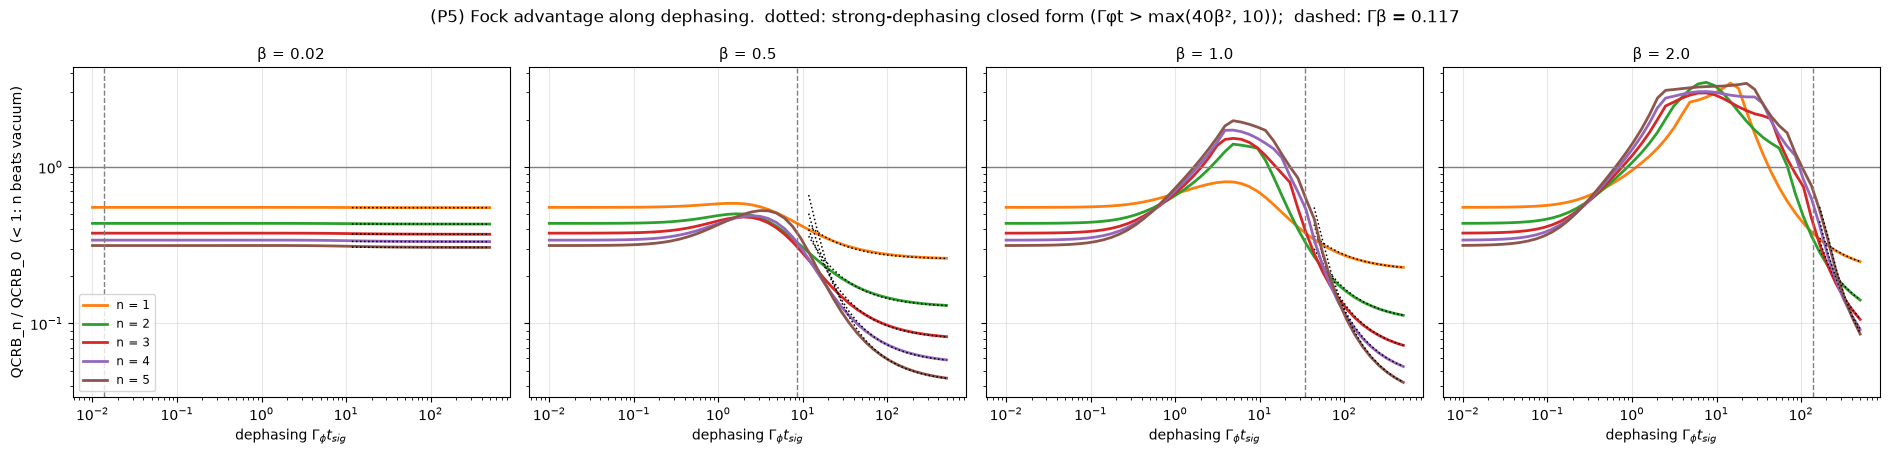

In [8]:
# P5. The re-entrance depends on the signal size (Notion §3: strong-noise coefficients are signal-dependent).
# QCRB_n / QCRB_0 along dephasing for four β. Below 1 means |n> beats the vacuum.
# Small-signal limit: every state's QCRB is multiplied by the same 1/f², f = (2/Γφt)(1 − e^{−Γφt/2}),
# so the ratios stay at their noiseless values and nothing re-enters.
gline = 10 .^ range(-2, log10(500), length=50)
βs_cut = (0.02, 0.5, 1.0, 2.0)
cuts = Dict(b => fill(NaN, length(N_VALS), length(gline)) for b in βs_cut)
GC.gc()   # finalize Python (PyPlot) objects on the main thread first: a PyCall finalizer on a worker thread segfaults
Threads.@threads :dynamic for idx in 1:(length(βs_cut)*length(gline))
    ib, ig = fldmod1(idx, length(gline))
    q, _ = min_qcrbs(βs_cut[ib], gline[ig], 0.0, 0.0)
    cuts[βs_cut[ib]][:, ig] = q
end
fig, axs = subplots(1, 4, figsize=(19, 4.6), sharey=true)
for (m, b) in enumerate(βs_cut)
    ax = axs[m]; Q = cuts[b]
    for (k, n) in enumerate(N_VALS[2:end])
        ax.plot(gline, Q[k+1, :] ./ Q[1, :], "-", color=N_COLORS[n+1], lw=2, label="n = $n")
        gs = gline[strong_valid.(b, gline)]
        isempty(gs) || ax.plot(gs, [min_qcrb_strong(n; β=b, Gphi=g) / min_qcrb_strong(0; β=b, Gphi=g) for g in gs], ":", color="black", lw=1.1)
    end
    ax.axhline(1, color="gray", lw=1)
    ax.axvline(4b^2 / 0.117, color="gray", ls="--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(alpha=0.3)
    ax.set_xlabel(L"dephasing $\Gamma_\phi t_{sig}$"); ax.set_title("β = $b", fontsize=11)
end
axs[1].set_ylabel("QCRB_n / QCRB_0  (< 1: n beats vacuum)"); axs[1].legend(fontsize=8.5, loc="lower left")
fig.suptitle("(P5) Fock advantage along dephasing.  dotted: strong-dephasing closed form (Γφt > max(40β², 10));  dashed: Γβ = 0.117", fontsize=12)
tight_layout(); savefig(joinpath(PLOT_DIR, "dephasing_P5_ratio_cuts.png"), dpi=130, bbox_inches="tight"); display(fig); close(fig)

# small-signal check: QCRB_n(Γφ) / QCRB_n(0) vs 1/f²
b = 0.002
q0, _ = min_qcrbs(b, 0.0, 0.0, 0.0)
println("small signal β = $b: QCRB_n(Γφt) / QCRB_n(0) · f²  (1 means the 1/f² law holds; same for every n)")
for g in (0.1, 1.0, 10.0, 100.0)
    q, _ = min_qcrbs(b, g, 0.0, 0.0); f = (2 / g) * (1 - exp(-g / 2))
    @printf("  Γφt = %6.1f:  %s\n", g, join([@sprintf("%.5f", q[k] / q0[k] * f^2) for k in eachindex(N_VALS)], "  "))
end

## 8. P6: heating limits the return

Real heating adds to Γβ, and it multiplies V_n by e^{−4α²Γh t}, which penalises the large α the higher states need. Hot bath Γc = Γh, β = 1.

(Γφt, Γh t) map, hot bath, β = 1: 36 × 24 points in 99 s; max tail 5.6e-12
closed-form n* = engine n* on 203 / 216 points with Γφt > max(40β², 10)
  n = 1 returns at strong dephasing up to Γh·t = 0.300
  n = 2 returns at strong dephasing up to Γh·t = 0.111
  n = 3 returns at strong dephasing up to Γh·t = 0.053
  n = 4 returns at strong dephasing up to Γh·t = 0.041
  n = 5 returns at strong dephasing up to Γh·t = 0.032

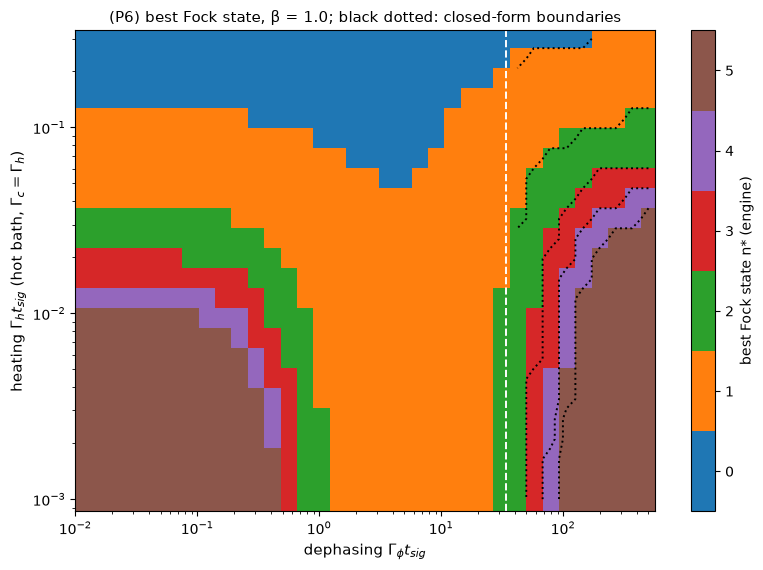

In [9]:
# P6. Heating bounds the return: hot bath Γc = Γh, β = 1, map over (Γφt, Γh t).
# Real heating adds to Γβ (D = Γh t + 4β²/Γφt) and multiplies V_n by e^{-4α²Γh t}, which penalises the
# large α that the higher states need.
function phase_map_heating(; β=1.0, gphi_range=(1e-2, 500.0), gh_range=(1e-3, 0.3), nx=36, ny=24)
    gps = 10 .^ range(log10(gphi_range[1]), log10(gphi_range[2]), length=nx)
    ghs = 10 .^ range(log10(gh_range[1]), log10(gh_range[2]), length=ny)
    Q = fill(NaN, length(N_VALS), ny, nx); tails = zeros(ny, nx)
    t0 = time()
    GC.gc()   # finalize Python (PyPlot) objects on the main thread first: a PyCall finalizer on a worker thread segfaults
    Threads.@threads :dynamic for idx in 1:(nx*ny)
        iy, ix = fldmod1(idx, nx)
        q, tl = min_qcrbs(β, gps[ix], ghs[iy], ghs[iy])
        Q[:, iy, ix] = q; tails[iy, ix] = tl
    end
    @printf("(Γφt, Γh t) map, hot bath, β = %g: %d × %d points in %.0f s; max tail %.1e\n", β, nx, ny, time() - t0, maximum(tails))
    return (gps=gps, ghs=ghs, Q=Q, tails=tails, β=β)
end
ph = phase_map_heating()
ns_h = nstar_of(ph.Q)
ns_hc = nstar_strong(ph.gps, ph.ghs; β=ph.β)
valid_h = [strong_valid(ph.β, g) for _ in ph.ghs, g in ph.gps]
@printf("closed-form n* = engine n* on %d / %d points with Γφt > max(40β², 10)\n", count(ns_h[valid_h] .== ns_hc[valid_h]), count(valid_h))

fig, ax = subplots(1, 1, figsize=(8.2, 5.8))
im = ax.pcolormesh(ph.gps, ph.ghs, ns_h, cmap=mcolors.ListedColormap(N_COLORS[1:length(N_VALS)]), vmin=-0.5, vmax=N_VALS[end] + 0.5, shading="nearest")
cb = fig.colorbar(im, ax=ax, ticks=N_VALS); cb.set_label("best Fock state n* (engine)")
cl = copy(ns_hc); cl[.!valid_h] .= NaN
ax.contour(ph.gps, ph.ghs, cl, levels=N_VALS[1:end-1] .+ 0.5, colors="black", linewidths=1.4, linestyles=":")
ax.axvline(4ph.β^2 / 0.117, color="white", ls="--", lw=1.4)
setup_log_axes!(ax, L"dephasing $\Gamma_\phi t_{sig}$", L"heating $\Gamma_h t_{sig}$ (hot bath, $\Gamma_c = \Gamma_h$)",
                "(P6) best Fock state, β = $(ph.β); black dotted: closed-form boundaries")
tight_layout(); savefig(joinpath(PLOT_DIR, "dephasing_P6_heating_bounds_return.png"), dpi=130, bbox_inches="tight"); display(fig); close(fig)
for n in N_VALS[2:end]
    rows = [i for i in eachindex(ph.ghs) if any(ns_h[i, strong_valid.(ph.β, ph.gps)] .== n)]
    isempty(rows) ? @printf("  n = %d never returns at strong dephasing\n", n) :
                    @printf("  n = %d returns at strong dephasing up to Γh·t = %.3f\n", n, ph.ghs[maximum(rows)])
end

## 9. Verdict

| Claim | Status | Evidence |
| --- | --- | --- |
| Re-entrance exists: n* falls to low n, then rises again with dephasing | **Numerically verified** | P1: at β = 0.9, n* = 5 → 3 → 2 → 1 → 2 → 3 → 4 → 5 along Γφt; at β = 2.2 it reaches the vacuum and returns. With a hot bath (P6), n = 2…5 return at Γφt ≳ 30–100. |
| O1: the map is converged (Notion §10 guardrail) | **Numerically verified** | P2: cutoff 61 → 91, steps × 2, α grid to 4.5: max ΔQCRB/QCRB = 3.2e-3, **0 changes of n*** on 84 points. Tail population ≤ 2.4e-16. |
| O1: benchmarked against an independent model | **Numerically verified** | Closed form (Block 4) and engine pick the same n* on 208/220 points (P1) and 203/216 (P6) where it applies, Γφt > max(40β², 10); the misses sit on boundaries. Min QCRB agrees to 1–2% at Γφt = 300. |
| M1/M2: the dephased drive is a hot bath Γβ = 4β²/Γφt | **Numerically verified** | P3-a: population trace distance 8e-2 (Γφt = 10, outside validity), 8e-3 (30), 3e-4 (300). The right edge of the low-n island follows the line Γβ = 0.117 (P1, P5). |
| M3: higher n wins because the contrast term weights large α | **Derived + numerically verified** | P4: max contrast FOM 0.65, 3.2, 7.0, 11.6, 16.8, 22.6 for n = 0…5 (×35 from n = 0 to 5) against phase FOM 0.092…0.293 (×3.2). In P1-b the gain over vacuum reaches 13 dB at strong dephasing and β ≈ 1. |
| O2/O3: depends on the signal, no re-entrance for β → 0 | **Numerically verified** | P5: at β = 0.02 the ratios QCRB_n/QCRB_0 stay flat; QCRB_n(Γφ)/QCRB_n(0)·f² = 1.0000–1.0006 for all n up to Γφt = 100. The island only exists for β ≳ 0.4. |
| M4: heating limits the return | **Numerically verified** | P6: n returns at strong dephasing only up to Γh·t = 0.30, 0.11, 0.053, 0.041, 0.032 for n = 1…5, roughly the predicted O(0.1/n) scaling. |

**Caveats.**

- Without any bath (P1), "higher n" means "the largest n searched" (n = 5): outside the island, more n is always better. A finite optimum appears only with a real bath (P6).
- The returning region sits at QCRB 10–1000× the noiseless vacuum value. The **relative** Fock gain is large there, but the absolute sensitivity is poor.
- Model: ideal signal drive, Lindblad noise, instantaneous readout (validated to ≈ 4% in 1120 when the readout is 10× faster than the signal).